# Module 1 — Language detection with fastText

**Goal:** given any message, say which language it is written in: `en` (English), `fr` (French) or `tn_latin` (Tunisian Arabizi).

```
"chnowa el ta9s f jarba ghodwa ?"   →   model   →   tn_latin  (98% sure)
```

The chatbot needs this first, so it can answer **in the same language** as the user.

### How to use this notebook
- A notebook is a list of **cells**. Text cells (like this one) explain; code cells run Python.
- Run a code cell with **Shift + Enter**. Its output appears right under it.
- Run the cells **from top to bottom**, in order: later cells use what earlier cells created.

### Reminder: the three sets of data
| Set | Size | Used for |
|---|---|---|
| **train** | 3,161 messages | the model **learns** from these |
| **val** (validation) | 684 messages | **we** check the model on these and make our choices (settings, number of epochs) |
| **test** | 674 messages | the **final exam**, used once at the very end of the project. **Not used in this notebook.** |

The model never learns from val: that's what makes val a fair check of how it does on **new** messages.

## 0. Setup

This cell:
1. finds the project folder (the one containing `CLAUDE.md`), so Python can import **our own code** from `src/`;
2. imports `fasttext` (the library) and our `normalize()` cleaning function — the same one the chatbot will use;
3. points to the two files prepared in step 3: `train.txt` and `val.txt`.

In [13]:
import sys, re
from pathlib import Path
from collections import Counter

# Walk up from the notebook's folder until we find the project root (the folder with CLAUDE.md)
ROOT = Path.cwd()
while not (ROOT / "CLAUDE.md").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))   # lets us write: from src.... import ...

import fasttext
from src.preprocessing.normalize import normalize

DATA = ROOT / "data" / "processed" / "fasttext_lang"
LANGS = ["en", "fr", "tn_latin"]

print("Project root:", ROOT)
print("Files found: ", sorted(p.name for p in DATA.glob("*.txt")))

Project root: c:\Users\medbe\OneDrive\Desktop\travel chatbot
Files found:  ['train.txt', 'val.txt']


## 1. Look at the data

Each line of `train.txt` / `val.txt` is one message in fastText's format:
```
__label__tn_latin 9adech billet el car l tounes ?
```
- the part before the first space is the **label** (the correct answer, "the truth");
- the rest is the **text**, already cleaned with `normalize()`.

The function below reads a file and splits every line into its label and its text, so we can look at them and, later, compare the model's answers with the truth.

**What to check in the output:** the three languages should have about the same number of messages (a *balanced* dataset), so the model is not pushed toward one language just because it saw it more often.

In [14]:
def read_fasttext_file(path):
    """Return two lists of the same length: labels (the truth) and texts."""
    labels, texts = [], []
    for line in open(path, encoding="utf-8"):
        label, text = line.rstrip("\n").split(" ", 1)   # split at the FIRST space only
        labels.append(label.replace("__label__", ""))
        texts.append(text)
    return labels, texts

train_labels, train_texts = read_fasttext_file(DATA / "train.txt")
val_labels, val_texts = read_fasttext_file(DATA / "val.txt")

print("TRAIN:", len(train_texts), "messages", dict(Counter(train_labels)))
print("VAL:  ", len(val_texts), "messages", dict(Counter(val_labels)))
print()
print("First 10 training messages:")
for label, text in list(zip(train_labels, train_texts))[:10]:
    print(f"  {label:9s} | {text}")

TRAIN: 3161 messages {'fr': 1058, 'tn_latin': 1054, 'en': 1049}
VAL:   684 messages {'en': 225, 'fr': 231, 'tn_latin': 228}

First 10 training messages:
  fr        | il existe un e-visa pour rome
  fr        | je peux prendre la voiture à aïn draham et la rendre à francfort ?
  tn_latin  | najjem ne5ou bagage cabine sghir w valise en soute ?
  tn_latin  | 9adech billet el car l tounes ?
  en        | how much is a taxi from the airport to lisbon
  fr        | comment se deplacer a doha sans voiture ?
  tn_latin  | hotel fi sousse fih piscine couverte ?
  tn_latin  | b9adech valise zeyda fi vol l roma ?
  fr        | je cherche une activité originale à milan pour deux personnes .
  en        | explain what cloud storage means in simple terms .


## 2. Which clues does the data contain?

Before training, let's measure two "clues" a human would use, per language:
- **a digit inside a word** (like `9adech`, `m3a`, `b7ar`, `8odwa`) — the Arabizi letters 3, 5, 7, 8, 9;
- **an accented letter** (é, è, à, ç, ô…) — typical of French.

**Why this matters:** if every Tunisian message had a digit and every French one an accent, the task would be trivial and one rule would do. The output will show that these clues are strong but **not present in every message**. That's exactly why we need a model that **combines many small clues** (the character pieces) instead of one hand-written rule.

In [15]:
digit_in_word = re.compile(r"[a-z][35789]|[35789][a-z]")   # a letter next to an Arabizi digit
accent = re.compile(r"[éèêëàâùûçôîï]")

print(f"{'language':9s} | {'avg words':>9s} | {'digit inside a word':>19s} | {'accented letter':>15s}")
for lang in LANGS:
    msgs = [t for l, t in zip(train_labels, train_texts) if l == lang]
    avg_words = sum(len(t.split()) for t in msgs) / len(msgs)
    pct_digit = 100 * sum(bool(digit_in_word.search(t)) for t in msgs) / len(msgs)
    pct_accent = 100 * sum(bool(accent.search(t)) for t in msgs) / len(msgs)
    print(f"{lang:9s} | {avg_words:9.1f} | {pct_digit:18.1f}% | {pct_accent:14.1f}%")

language  | avg words | digit inside a word | accented letter
en        |      10.2 |                0.5% |            0.3%
fr        |       9.9 |                0.0% |           69.5%
tn_latin  |       7.9 |               60.7% |           13.1%


### What the table above tells us

| | digit inside a word | accented letter |
|---|---|---|
| **tn_latin** | 60.7% | 13.1% |
| **fr** | 0% | 69.5% |
| **en** | 0.5% | 0.3% |

- **39% of Tunisian messages have no Arabizi digit** (e.g. `hotel fi sousse fih piscine couverte ?`). A rule "digit → Tunisian" would miss all of them.
- **30% of French messages have no accent** (e.g. `comment se deplacer a doha sans voiture ?`), because people often type without accents.
- **13% of Tunisian messages contain accents**, from French words mixed in (`séjour`, `visites guidées`): that's code-switching.
- Tunisian messages are **shorter** (7.9 words on average vs ~10).

**Conclusion:** no single clue is enough. We need a model that **adds up many small clues**: that's exactly what fastText does with its weight table.

## 3. First training

### What "training" means here (short reminder)
1. The model starts with a **weight table full of zeros**: one row per word (or piece), one column per language. It knows nothing.
2. It reads the training messages **one by one**. For each one it guesses the language, compares its guess with the **label** (the truth), and **nudges the weights** of the words in that message toward the right language.
3. One full pass over all 3,161 messages = one **epoch**. It repeats this for several epochs.
4. At the end, the weight table is "filled": words like `9adech` point strongly to Tunisian, `combien` to French, `the` to English.

### The code, line by line
`fasttext.train_supervised(...)` does all of the above in one call. The arguments are the **hyperparameters** (settings we choose):

| argument | value | meaning |
|---|---|---|
| `input` | `train.txt` | the training file (**only train**, never val or test) |
| `epoch` | 5 | 5 passes over the training data (fastText's default) |
| `lr` | 0.1 | learning rate: how big each correction is (fastText's default) |
| `dim` | 50 | size of fastText's internal vectors |
| `bucket` | 200,000 | size of the hash table: keeps the model file small |
| `thread` | 1 | use one CPU thread: slower but gives **exactly the same model every run** |
| `seed` | 42 | same random start every run (reproducibility) |
| `verbose` | 0 | don't print progress |

**Notice what is missing:** `minn` and `maxn` are not set, so they keep fastText's default of **0** → **character pieces are OFF**. This first model only looks at **whole words**. We start simple on purpose, to have something to compare against.

### Reading the predictions
`model.predict(text, k=3)` returns the **3 languages with their probabilities**, highest first. The helper `show_predictions` prints them for a few messages, including some tricky ones:
- a code-switched message (`nheb billet l paris ghodwa`),
- a Tunisian message with only one dialect word (`location karhba f sousse`),
- French **without accents**,
- **typos** (`jarbaa`, `ghodwaa`),
- a message with **no language clue at all** (`paris ?`).

In [16]:
model_a = fasttext.train_supervised(
    input=str(DATA / "train.txt"),
    epoch=5,
    lr=0.1,
    dim=50,
    bucket=200_000,
    thread=1,
    seed=42,
    verbose=0,
)

def show_predictions(model, messages):
    # Print the 3 languages and their probabilities for each message (highest first).
    for msg in messages:
        labels, probs = model.predict(normalize(msg), k=3)   # same cleaning as the training data
        scores = "   ".join(f"{l.replace('__label__', ''):8s} {p:6.1%}" for l, p in zip(labels, probs))
        print(f"{msg:40s} ->  {scores}")

TRY_THESE = [
    "nheb billet l paris ghodwa",
    "location karhba f sousse",
    "chnowa el ta9s f jarbaa ghodwaa ?",
    "meteo a djerba demain",
    "c'est combien le billet pour paris ?",
    "weather in tunis tomorrow",
    "nhebek barcha",
    "paris ?",
]
show_predictions(model_a, TRY_THESE)

nheb billet l paris ghodwa               ->  tn_latin 100.0%   en         0.0%   fr         0.0%
location karhba f sousse                 ->  tn_latin  99.9%   fr         0.0%   en         0.0%
chnowa el ta9s f jarbaa ghodwaa ?        ->  tn_latin 100.0%   en         0.0%   fr         0.0%
meteo a djerba demain                    ->  fr        72.5%   en        25.2%   tn_latin   2.2%
c'est combien le billet pour paris ?     ->  fr        99.6%   tn_latin   0.3%   en         0.0%
weather in tunis tomorrow                ->  en       100.0%   tn_latin   0.0%   fr         0.0%
nhebek barcha                            ->  tn_latin  96.8%   fr         2.0%   en         1.2%
paris ?                                  ->  tn_latin  83.3%   fr        10.6%   en         6.1%


### What we learned from these predictions
- Clear messages (Tunisian with dialect words, French with accents, English) get **very confident, correct** answers, even with typos (`chnowa el ta9s f jarbaa ghodwaa ?` → Tunisian 100%).
- **French without accents is less sure:** `meteo a djerba demain` → French only **72.5%** (English 25%). Accents are one of the strongest French clues, and here they are missing.
- **`paris ?` → Tunisian ~83%**, although this message contains no language at all. A check showed that even `?` alone → Tunisian 92% and `london ?` → Tunisian 78%, while `paris` actually appears **more** in English and French training messages than in Tunisian ones.
  - So Tunisian has become the model's **default answer when there is no real evidence**. Likely reason: English and French are explained by very frequent, distinctive words (`the`, `is`, `de`, `le`, `combien`), while Tunisian evidence is spread over many spelling variants, so the model also pushes shared tokens (`?`, city names) toward Tunisian.
  - This is a small case of **shortcut learning**, and the model is **badly calibrated** here: 83% sure when the honest answer is "I can't tell".
  - **Decision:** this is handled in the chatbot, not in the model. A short message with no language evidence keeps the **language of the conversation**. For a first message with no evidence, a deliberate default language is used.

## 4. Accuracy: how good is the model, as one number?

### What accuracy is
**Accuracy = number of messages where the predicted language equals the label ÷ total number of messages.**

Example: 684 val messages, 683 predicted correctly → 683 / 684 = **99.85%**.

The model's answer for one message is the language with the **highest probability** (the first label returned by `predict`). It is either right or wrong; accuracy counts how often it is right.

### How the code computes it (no magic)
For each message:
1. `model.predict(text)` → the model's answer (e.g. `tn_latin`);
2. compare it with the **label** (the truth) → right or wrong;
3. count.

We do it on **both** sets:
- **train accuracy**: on the messages the model **learned from**, i.e. how well it learned its homework;
- **val accuracy**: on messages it **never saw**, i.e. how well it handles new messages. **This is the number that matters.**

We also compute accuracy **per language** (the project target is **≥ 90% for each language**, not only overall), and we print **every mistake** with the model's probabilities, because looking at errors teaches more than the number itself.

The texts in `train.txt` / `val.txt` are already cleaned with `normalize()` (done in step 3), so we pass them to the model directly.

In [17]:
def evaluate(model, labels, texts):
    # Predict every message, compare with the label, and return: overall accuracy,
    # accuracy per language, and the list of mistakes.
    predicted = [model.predict(t)[0][0].replace("__label__", "") for t in texts]
    correct = [p == l for p, l in zip(predicted, labels)]
    overall = sum(correct) / len(correct)
    per_lang = {lang: sum(c for c, l in zip(correct, labels) if l == lang) / labels.count(lang) for lang in LANGS}
    mistakes = [(l, p, t) for l, p, t, c in zip(labels, predicted, texts, correct) if not c]
    return overall, per_lang, mistakes

for set_name, labels, texts in [("TRAIN", train_labels, train_texts), ("VAL", val_labels, val_texts)]:
    overall, per_lang, mistakes = evaluate(model_a, labels, texts)
    print(f"{set_name}: accuracy {overall:.2%}  ({len(texts) - len(mistakes)} / {len(texts)} correct)")
    print("   per language:", "  ".join(f"{lang} {acc:.2%}" for lang, acc in per_lang.items()))
    for truth, pred, text in mistakes:
        labels_k, probs_k = model_a.predict(text, k=3)
        probs = "  ".join(f"{l.replace('__label__', '')} {p:.0%}" for l, p in zip(labels_k, probs_k))
        print(f"   MISTAKE  truth={truth:8s} predicted={pred:8s} | {text}   [{probs}]")
    print()

TRAIN: accuracy 99.97%  (3160 / 3161 correct)
   per language: en 100.00%  fr 100.00%  tn_latin 99.91%
   MISTAKE  truth=tn_latin predicted=fr       | kifech n7adher thé à la menthe bel na3na3 frais ?   [fr 59%  tn_latin 40%  en 1%]

VAL: accuracy 99.85%  (683 / 684 correct)
   per language: en 99.56%  fr 100.00%  tn_latin 100.00%
   MISTAKE  truth=en       predicted=tn_latin | flight nabeul zarzis today   [tn_latin 49%  en 38%  fr 13%]



## 5. Loss, and the learning curves

### What loss is
Accuracy only says **right or wrong**. **Loss** also measures **how confident** the model was in the right answer.

For one message: **loss = −log(probability the model gave to the correct language)**.

| probability given to the correct language | loss for that message |
|---|---|
| 99% | 0.01 |
| 90% | 0.11 |
| 60% | 0.51 |
| 33% (pure guessing among 3 languages) | **1.10** |
| 5% (confidently wrong) | 3.00 |

The loss of a whole set is the **average** over its messages. **Lower is better**; 0 would mean "always 100% sure and always right". A value around **1.10** means the model is just guessing.

**Why look at loss if we have accuracy?** Two models can have the same accuracy while one is barely right (51%) and the other clearly right (98%). Loss sees the difference, so it changes **earlier and more smoothly** than accuracy, and it is what training actually tries to make small.

### The experiment
fastText cannot report its scores after each epoch, so we do it the simple way: we **train 30 separate models**, with 1, 2, 3 … 30 epochs (same settings as `model_a` otherwise), and for each one we measure **loss and accuracy on train and on val**.

Then we draw the **learning curves**: x-axis = number of epochs, y-axis = loss (left graph) or accuracy (right graph), one line for **train**, one for **val**.

### How to read them (reminder)
- both lines go down / up and stay **close together** → **good fit**;
- both stay **bad** → **underfitting** (not learning enough);
- train keeps improving while **val gets worse** (gap growing, val loss going back up) → **overfitting** (memorizing).

The loss graph uses a **logarithmic y-axis**: each grid line is **10× smaller** than the one above. Without it, all the small values after epoch 5 would look like a flat line at 0 and we could not compare train and val.

epochs | train loss  val loss | train acc  val acc
     1 |     0.6458    0.6432 |    96.20%   96.20%
     2 |     0.0817    0.0786 |    99.18%   99.27%
     3 |     0.0385    0.0397 |    99.75%   99.56%
     5 |     0.0163    0.0210 |    99.97%   99.85%
     8 |     0.0077    0.0136 |   100.00%   99.71%
    12 |     0.0042    0.0101 |   100.00%   99.71%
    20 |     0.0021    0.0076 |   100.00%   99.71%
    30 |     0.0012    0.0064 |   100.00%   99.71%


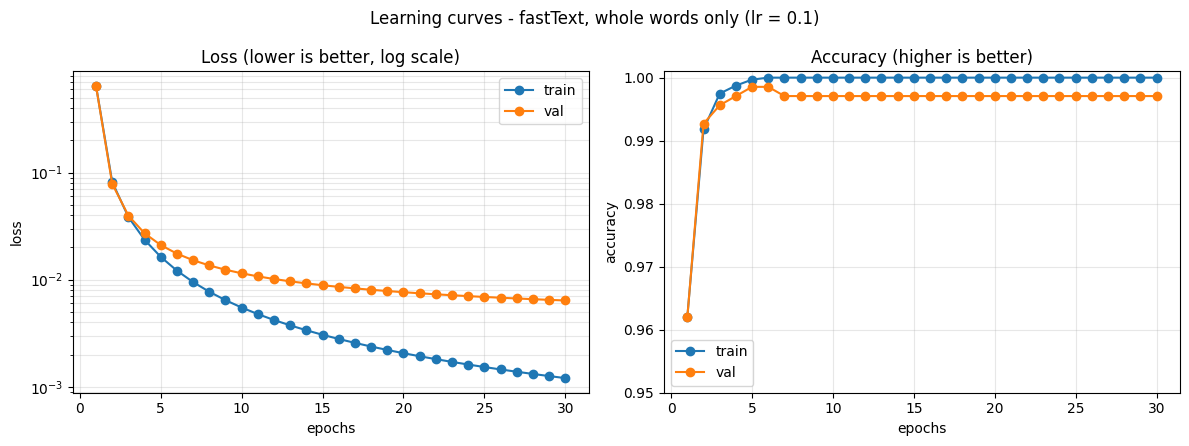

In [18]:
import math
import matplotlib.pyplot as plt

def loss_and_accuracy(model, labels, texts):
    # Average loss = mean of -log(probability given to the correct language); accuracy = share of right answers.
    total_loss, correct = 0.0, 0
    for label, text in zip(labels, texts):
        langs, probs = model.predict(text, k=3)                  # all 3 languages with their probabilities
        langs = [l.replace("__label__", "") for l in langs]
        prob_of_truth = dict(zip(langs, probs))[label]
        total_loss += -math.log(max(prob_of_truth, 1e-9))         # 1e-9 avoids log(0)
        correct += langs[0] == label                              # langs[0] = the model's answer
    return total_loss / len(texts), correct / len(texts)

EPOCHS = list(range(1, 31))
curves = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for ep in EPOCHS:
    m = fasttext.train_supervised(input=str(DATA / "train.txt"), epoch=ep, lr=0.1, dim=50,
                                  bucket=200_000, thread=1, seed=42, verbose=0)
    train_loss, train_acc = loss_and_accuracy(m, train_labels, train_texts)
    val_loss, val_acc = loss_and_accuracy(m, val_labels, val_texts)
    for key, value in [("train_loss", train_loss), ("val_loss", val_loss), ("train_acc", train_acc), ("val_acc", val_acc)]:
        curves[key].append(value)

print(f"{'epochs':>6} | {'train loss':>10} {'val loss':>9} | {'train acc':>9} {'val acc':>8}")
for i, ep in enumerate(EPOCHS):
    if ep in (1, 2, 3, 5, 8, 12, 20, 30):
        print(f"{ep:6d} | {curves['train_loss'][i]:10.4f} {curves['val_loss'][i]:9.4f} | "
              f"{curves['train_acc'][i]:9.2%} {curves['val_acc'][i]:8.2%}")

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_loss.plot(EPOCHS, curves["train_loss"], "o-", label="train")
ax_loss.plot(EPOCHS, curves["val_loss"], "o-", label="val")
ax_loss.set_yscale("log")
ax_loss.set(title="Loss (lower is better, log scale)", xlabel="epochs", ylabel="loss")
ax_acc.plot(EPOCHS, curves["train_acc"], "o-", label="train")
ax_acc.plot(EPOCHS, curves["val_acc"], "o-", label="val")
ax_acc.set(title="Accuracy (higher is better)", xlabel="epochs", ylabel="accuracy", ylim=(0.95, 1.001))
for ax in (ax_loss, ax_acc):
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
fig.suptitle("Learning curves - fastText, whole words only (lr = 0.1)")
fig.tight_layout()

FIGURES = ROOT / "eval" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES / "lang_learning_curves_words.png", dpi=150)
plt.show()

### Reading the curves (whole words only)

**What changes between the points:** only `epoch`. Each point is a **separate model trained from scratch** with 1, 2, … 30 epochs; all other settings (and the seed) are identical. fastText lowers its learning rate linearly from 0.1 to 0 over the *whole* training, so each point shows "the final quality of a model trained for N epochs".

**Epoch 1 → 2: loss drops from 0.65 to 0.08, accuracy only from 96% to 99%.** After 1 epoch the model already puts the right language on top almost always, but it is **hesitant** (≈ 55% → loss ≈ 0.6). With 2 epochs it has done about twice as much correcting, its weights grow, and it becomes **confident** (≈ 92% → loss ≈ 0.08). Accuracy only checks "is the right answer on top?"; loss also checks "how sure?".

**The two loss lines separate at the end** (train ≈ 0.001, val ≈ 0.006): the model becomes almost 100% sure on the messages it has seen 30 times, faster than on new ones. That is the **beginning of memorization**. But:
- val loss **never goes back up** (no U shape) and val accuracy only moves by **one message** (99.85% → 99.71%): no harmful overfitting;
- the log scale makes the gap look bigger than it is: on average ≈ 99.9% vs ≈ 99.4% for the right language.

**Hidden cost of many epochs:** the model gets more confident about *everything*, including ambiguous messages (`paris ?`: 83% Tunisian at 5 epochs, 94% at 25, with lr = 0.1). Val cannot show this because it contains almost no ambiguous messages.

**Diagnosis: good fit, with mild memorization after ~8 epochs.** A sensible range is **5–10 epochs**. Our val set is too easy to separate good settings from very good ones, so the final choice will also use a small **challenge set** of tricky messages.

## 6. Turning character pieces on

Now the same experiment, with one change: **`minn=2, maxn=5`**, i.e. every word is also cut into all its pieces of 2 to 5 letters (`ta9s` → `<t`, `ta`, `a9`, `9s`, `<ta`, `ta9`, … plus the word itself). Everything else stays the same (`lr=0.1`, same seed).

**Why we expect it to help:** pieces let the model recognise spellings it has never seen (`ghodwaa`, `jarbaa`, `8odwa`) because they share most pieces with known words.

**What to look for in the graphs:** the **start** of the curves. Compare the loss after 1, 2 and 3 epochs with the "pure guessing" value of **1.10**, and compare it with the accuracy at the same epochs. Something unusual happens; we'll explain it after you run the cell.

The dashed line is the **val** curve of the previous experiment (whole words only), for comparison. This cell trains 30 bigger models, so it takes about half a minute.

epochs | train loss  val loss | train acc  val acc
     1 |     1.0985    1.0985 |    83.30%   82.60%
     2 |     1.0980    1.0980 |    95.76%   95.32%
     3 |     1.0922    1.0926 |    96.36%   96.05%
     4 |     1.0374    1.0407 |    96.27%   95.76%
     5 |     0.7364    0.7515 |    97.82%   97.37%
     8 |     0.1056    0.1236 |    99.37%   98.83%
    12 |     0.0396    0.0564 |    99.68%   99.12%
    20 |     0.0156    0.0308 |    99.97%   99.42%
    30 |     0.0080    0.0214 |   100.00%   99.42%


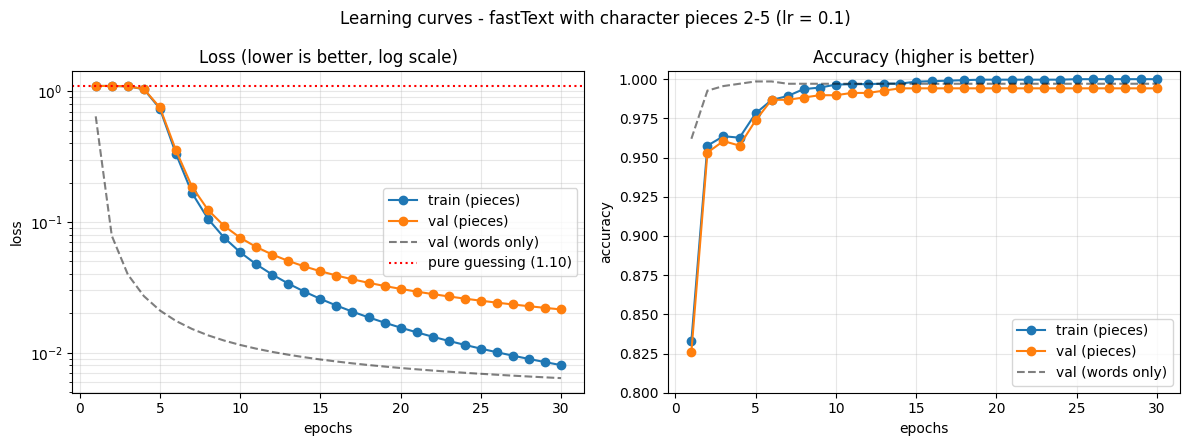

In [19]:
curves_chars = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for ep in EPOCHS:
    m = fasttext.train_supervised(input=str(DATA / "train.txt"), epoch=ep, lr=0.1, dim=50,
                                  minn=2, maxn=5,                       # <- the only change: character pieces ON
                                  bucket=200_000, thread=1, seed=42, verbose=0)
    train_loss, train_acc = loss_and_accuracy(m, train_labels, train_texts)
    val_loss, val_acc = loss_and_accuracy(m, val_labels, val_texts)
    for key, value in [("train_loss", train_loss), ("val_loss", val_loss), ("train_acc", train_acc), ("val_acc", val_acc)]:
        curves_chars[key].append(value)

print(f"{'epochs':>6} | {'train loss':>10} {'val loss':>9} | {'train acc':>9} {'val acc':>8}")
for i, ep in enumerate(EPOCHS):
    if ep in (1, 2, 3, 4, 5, 8, 12, 20, 30):
        print(f"{ep:6d} | {curves_chars['train_loss'][i]:10.4f} {curves_chars['val_loss'][i]:9.4f} | "
              f"{curves_chars['train_acc'][i]:9.2%} {curves_chars['val_acc'][i]:8.2%}")

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_loss.plot(EPOCHS, curves_chars["train_loss"], "o-", label="train (pieces)")
ax_loss.plot(EPOCHS, curves_chars["val_loss"], "o-", label="val (pieces)")
ax_loss.plot(EPOCHS, curves["val_loss"], "k--", alpha=0.5, label="val (words only)")
ax_loss.axhline(math.log(3), color="red", linestyle=":", label="pure guessing (1.10)")
ax_loss.set_yscale("log")
ax_loss.set(title="Loss (lower is better, log scale)", xlabel="epochs", ylabel="loss")
ax_acc.plot(EPOCHS, curves_chars["train_acc"], "o-", label="train (pieces)")
ax_acc.plot(EPOCHS, curves_chars["val_acc"], "o-", label="val (pieces)")
ax_acc.plot(EPOCHS, curves["val_acc"], "k--", alpha=0.5, label="val (words only)")
ax_acc.set(title="Accuracy (higher is better)", xlabel="epochs", ylabel="accuracy", ylim=(0.80, 1.005))
for ax in (ax_loss, ax_acc):
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
fig.suptitle("Learning curves - fastText with character pieces 2-5 (lr = 0.1)")
fig.tight_layout()
fig.savefig(FIGURES / "lang_learning_curves_chars.png", dpi=150)
plt.show()

### What happened with character pieces

**The puzzle:** for epochs 1–3 the loss stays at **1.0985 ≈ 1.10 = pure guessing**, while accuracy is already **83–96%**.

**Both are true at once: the model is right by a whisker.** After 1 epoch a Tunisian message gets something like `tn 33.36%  fr 33.33%  en 33.31%`. Accuracy only checks which language is on top → *correct*. Loss checks how much probability the right answer got → 33.36% → *guessing level*. The model has learned the right **direction**, but its weights are still **tiny**. (Accuracy alone would have hidden that this model is barely trained.)

**Why pieces make the start so slow:**
1. **The correction is shared among many more items.** The message vector is the *average* of its items: ~10 items with whole words, but **~120–150 items** with pieces of 2–5 letters. Each correction is spread over all of them, so each piece moves about **15× less** than a whole word did.
2. **Learning has to snowball.** fastText starts with the output table at **zero** and tiny random piece vectors. A score is roughly *(output table) × (average of piece vectors)*: small × small = tiny, so probabilities stay near 33%. Each correction makes both a bit bigger, so the next one has more effect, and learning **accelerates**: loss 1.09 (epoch 3) → 1.04 (4) → 0.74 (5) → 0.11 (8).

**Diagnosis: underfitting at the start** (the model has not had enough learning yet), not a bug. Fix: **more total learning**, i.e. more epochs or a **bigger learning rate**.

**Pieces vs words at 30 epochs, lr = 0.1:** val accuracy 99.42% vs 99.71%. This is **not a fair comparison yet**: the pieces model is still under-trained, and val barely contains what pieces are good at (typos and unseen spellings).

## 7. Tuning: trying several settings, judged on val

**Hyperparameter tuning** = train several models with different settings and keep the one that does best **on val**. This is exactly what val is for. (The test set is still untouched.)

We try a small **grid**: every combination of
- **features:** whole words only, or + character pieces 2–5;
- **learning rate (`lr`):** 0.1, 0.5, 1.0 (bigger = bigger corrections, faster learning, but riskier);
- **epochs:** 5, 10, 25.

That is 2 × 3 × 3 = **18 models**, about 10 seconds in total. For each one we report:
- **val accuracy** and **val loss** (lower loss = more confidently right on new messages);
- **`paris ?` top guess**: the language and confidence of the model's answer on our content-free example. A **lower** confidence is *better* here: the honest answer is "I can't tell" (~33% each). It is a small hint about **calibration**, i.e. whether the model's confidence can be trusted.

The table is sorted by val loss, best first.

In [20]:
results = []
for features in ["words", "pieces"]:
    pieces_args = dict(minn=2, maxn=5) if features == "pieces" else {}
    for lr in [0.1, 0.5, 1.0]:
        for ep in [5, 10, 25]:
            m = fasttext.train_supervised(input=str(DATA / "train.txt"), epoch=ep, lr=lr, dim=50,
                                          bucket=200_000, thread=1, seed=42, verbose=0, **pieces_args)
            val_loss, val_acc = loss_and_accuracy(m, val_labels, val_texts)
            paris_label, paris_prob = m.predict("paris ?")             # the top guess and its probability
            paris_guess = f"{paris_label[0].replace('__label__', '')} {paris_prob[0]:.0%}"
            results.append({"features": features, "lr": lr, "epochs": ep,
                            "val_loss": val_loss, "val_acc": val_acc, "paris_guess": paris_guess})

results.sort(key=lambda r: r["val_loss"])
print(f"{'features':8s} {'lr':>4s} {'epochs':>6s} | {'val loss':>8s} {'val acc':>8s} | {'paris ? top guess':>18s}")
for r in results:
    print(f"{r['features']:8s} {r['lr']:4.1f} {r['epochs']:6d} | {r['val_loss']:8.4f} {r['val_acc']:8.2%} | {r['paris_guess']:>18s}")

features   lr epochs | val loss  val acc |  paris ? top guess
words     0.5     25 |   0.0037   99.85% |       tn_latin 98%
words     1.0     25 |   0.0047   99.71% |             en 52%
words     0.5     10 |   0.0048   99.71% |       tn_latin 97%
words     1.0     10 |   0.0053   99.71% |             en 62%
words     1.0      5 |   0.0059   99.71% |             en 67%
words     0.5      5 |   0.0062   99.71% |       tn_latin 94%
pieces    1.0     25 |   0.0065   99.71% |       tn_latin 94%
words     0.1     25 |   0.0069   99.71% |       tn_latin 94%
pieces    0.5     25 |   0.0087   99.71% |       tn_latin 87%
pieces    1.0     10 |   0.0098   99.71% |       tn_latin 90%
words     0.1     10 |   0.0115   99.71% |       tn_latin 90%
pieces    1.0      5 |   0.0144   99.71% |       tn_latin 85%
pieces    0.5     10 |   0.0145   99.71% |       tn_latin 80%
words     0.1      5 |   0.0210   99.85% |       tn_latin 83%
pieces    0.5      5 |   0.0246   99.42% |       tn_latin 68%
pieces  

## 8. The challenge set: messages unlike our training data

### Why we need it
On val, almost all settings score 99.4–99.85% (only the under-trained pieces models with lr = 0.1 are lower, 97.4–99.0%): val is made the same way as train (same templates, same GPT style), so it is **too easy** to tell good settings from very good ones. Real users will type differently: typos, SMS style, French without accents, heavy code-switching, very short messages. A model can be excellent on data like its training data and weaker on real data; this gap is called **distribution shift**.

### What it is
`data/challenge/lang_challenge.jsonl`: **60 hand-written tricky messages** (20 per language), each tagged with what makes it hard, e.g.:
- `wats the weather like in tunis tmrw` (typos, SMS style)
- `est ce quon peut se baigner a hammamet en octobre` (French with no accents, no apostrophe)
- `location voiture f sousse ghodwa 9adeh ?` (heavy code-switching, spelling variant)
- `merci beaucoup`, `y3aychek barcha` (very short)

The Tunisian messages were reviewed by a native speaker.

### Its role
It is a **second validation set**, used together with val to choose the settings. It is **not** the final test: the test set stays untouched. The messages are raw, so we clean them with `normalize()` first, exactly like the chatbot will.

### A word of caution
With 60 messages, **one message = 1.7 percentage points**. A difference of 1 or 2 messages between two settings is mostly luck, not a real difference. Look for **clear** gaps and for **which kinds** of messages fail.

The code retrains the same 18 models as section 7 and counts how many challenge messages each gets right (sorted best first), then prints the mistakes of the top settings.

In [21]:
import json

challenge = [json.loads(line) for line in open(ROOT / "data" / "challenge" / "lang_challenge.jsonl", encoding="utf-8")
             if line.strip()]
ch_labels = [r["lang"] for r in challenge]
ch_texts = [normalize(r["text"]) for r in challenge]          # raw messages -> same cleaning as training
print("Challenge set:", len(challenge), "messages", dict(Counter(ch_labels)))

for r in results:                                             # the 18 settings from section 7
    pieces_args = dict(minn=2, maxn=5) if r["features"] == "pieces" else {}
    m = fasttext.train_supervised(input=str(DATA / "train.txt"), epoch=r["epochs"], lr=r["lr"], dim=50,
                                  bucket=200_000, thread=1, seed=42, verbose=0, **pieces_args)
    _, ch_per_lang, ch_mistakes = evaluate(m, ch_labels, ch_texts)
    r["challenge_correct"] = len(ch_texts) - len(ch_mistakes)
    r["challenge_per_lang"] = {lang: round(acc * ch_labels.count(lang)) for lang, acc in ch_per_lang.items()}
    r["challenge_mistakes"] = ch_mistakes

results.sort(key=lambda r: (-r["challenge_correct"], r["val_loss"]))
print(f"\n{'features':8s} {'lr':>4s} {'epochs':>6s} | {'challenge':>9s} {'en/fr/tn':>9s} | {'val acc':>7s} {'val loss':>8s} | {'paris ? top guess':>18s}")
for r in results:
    pl = r["challenge_per_lang"]
    print(f"{r['features']:8s} {r['lr']:4.1f} {r['epochs']:6d} | {r['challenge_correct']:6d}/60 "
          f"{pl['en']:>3d}/{pl['fr']}/{pl['tn_latin']} | {r['val_acc']:7.2%} {r['val_loss']:8.4f} | {r['paris_guess']:>18s}")

print("\nMistakes of the best 'words' setting and the best 'pieces' setting:")
for features in ["words", "pieces"]:
    best = next(r for r in results if r["features"] == features)
    print(f"  {features}, lr {best['lr']}, {best['epochs']} epochs:")
    for truth, pred, text in best["challenge_mistakes"]:
        print(f"     truth={truth:8s} predicted={pred:8s} | {text}")

Challenge set: 60 messages {'en': 20, 'fr': 20, 'tn_latin': 20}

features   lr epochs | challenge  en/fr/tn | val acc val loss |  paris ? top guess
words     1.0     25 |     59/60  20/19/20 |  99.71%   0.0047 |             en 52%
words     1.0     10 |     59/60  20/19/20 |  99.71%   0.0053 |             en 62%
words     1.0      5 |     58/60  20/19/19 |  99.71%   0.0059 |             en 67%
pieces    0.5     25 |     58/60  20/18/20 |  99.71%   0.0087 |       tn_latin 87%
pieces    1.0     10 |     58/60  20/18/20 |  99.71%   0.0098 |       tn_latin 90%
pieces    1.0      5 |     58/60  20/18/20 |  99.71%   0.0144 |       tn_latin 85%
pieces    0.5     10 |     58/60  20/18/20 |  99.71%   0.0145 |       tn_latin 80%
pieces    0.5      5 |     58/60  20/18/20 |  99.42%   0.0246 |       tn_latin 68%
pieces    0.1     25 |     58/60  20/18/20 |  99.42%   0.0250 |       tn_latin 62%
pieces    1.0     25 |     57/60  20/17/20 |  99.71%   0.0065 |       tn_latin 94%
pieces    0.1     10 |

## 9. The final model and its confusion matrix

### The choice
**Whole words only, `lr = 1.0`, `epoch = 10`** (other settings unchanged: `dim = 50`, `bucket = 200,000`, `thread = 1`, `seed = 42`). Why:
- best score on the challenge set (**59/60**, tied with the same setting at 25 epochs) and **99.71%** on val;
- **not over-confident** on content-free messages: `paris ?` → English 62% / Tunisian 37%, a hesitant guess, while most other settings say Tunisian at 83–98%. With `lr = 1.0` the strong default-to-Tunisian effect is gone;
- the 25-epoch version is practically identical (same accuracy, val loss 0.0047 vs 0.0053, `paris ?` → English 52%). The differences are too small to matter, so we keep 10 epochs (shorter training);
- smaller and faster than the character-pieces version.

Character pieces (58/60) would also have been a good choice: the difference is a single message.

### What a confusion matrix is
A table that shows **exactly which language gets confused with which**:
- each **row** = the **true** language;
- each **column** = the language the model **predicted**;
- each cell = **how many messages** fall in that combination.

```
                 predicted en   predicted fr   predicted tn
true en               224             0              1      ← 1 English message was called Tunisian
true fr                 1           230              0
true tn                 0             0            228
```
The **diagonal** (top-left to bottom-right) = correct answers. **Everything off the diagonal is a mistake**, and its position tells you the *kind* of mistake. With 3 languages, accuracy hides this; the matrix shows it.

### Precision, recall and F1, per language
Two different questions about one language, say Tunisian:
- **Recall (tn)**: of all the messages that **really are** Tunisian, how many did the model find? = diagonal ÷ **row** total. This is the "accuracy per language" from section 4, and the project target (**≥ 90% per language**) is about it.
- **Precision (tn)**: of all the messages the model **called** Tunisian, how many really were? = diagonal ÷ **column** total. Low precision means the model "over-uses" that language (remember the default-to-Tunisian effect).
- **F1** combines both into one number: 2 × P × R / (P + R). It is only high if **both** are high.

The code trains the final model, draws the confusion matrix for **val** and for the **challenge set**, prints precision / recall / F1 per language, and lists the remaining mistakes.

VAL:   precision  recall     F1
  en           99.56%  99.56% 99.56%
  fr          100.00%  99.57% 99.78%
  tn_latin     99.56% 100.00% 99.78%
  MISTAKE truth=en       predicted=tn_latin | flight nabeul zarzis today
  MISTAKE truth=fr       predicted=en       | dossier visa paris quels papiers

CHALLENGE:   precision  recall     F1
  en          100.00% 100.00% 100.00%
  fr          100.00%  95.00% 97.44%
  tn_latin     95.24% 100.00% 97.56%
  MISTAKE truth=fr       predicted=tn_latin | vol direct tunis istanbul svp



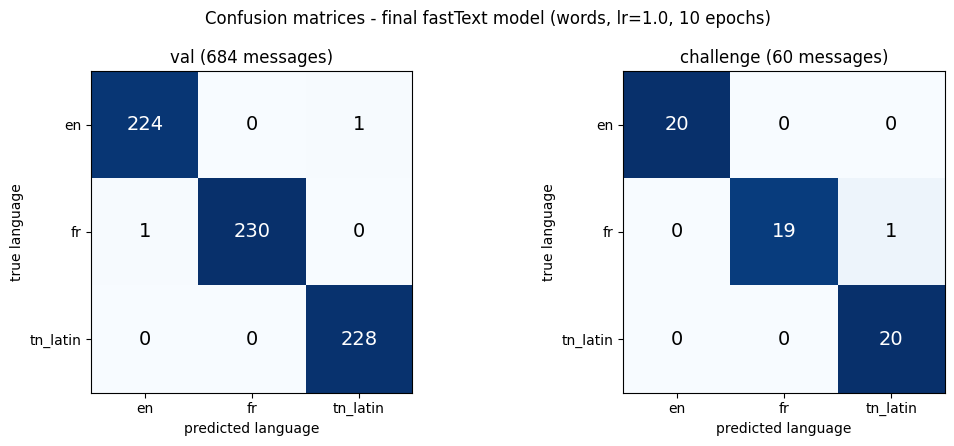

In [22]:
final_model = fasttext.train_supervised(input=str(DATA / "train.txt"), epoch=10, lr=1.0, dim=50,
                                        bucket=200_000, thread=1, seed=42, verbose=0)

def confusion_matrix(model, labels, texts):
    # matrix[true][predicted] = number of messages
    matrix = {t: {p: 0 for p in LANGS} for t in LANGS}
    for truth, text in zip(labels, texts):
        matrix[truth][model.predict(text)[0][0].replace("__label__", "")] += 1
    return matrix

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (set_name, labels, texts) in zip(axes, [("val", val_labels, val_texts), ("challenge", ch_labels, ch_texts)]):
    cm = confusion_matrix(final_model, labels, texts)
    grid = [[cm[t][p] for p in LANGS] for t in LANGS]
    ax.imshow(grid, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, grid[i][j], ha="center", va="center", fontsize=14,
                    color="white" if grid[i][j] > max(map(max, grid)) / 2 else "black")
    ax.set_xticks(range(3), LANGS)
    ax.set_yticks(range(3), LANGS)
    ax.set(title=f"{set_name} ({len(texts)} messages)", xlabel="predicted language", ylabel="true language")

    print(f"{set_name.upper()}:   {'precision':>9s} {'recall':>7s} {'F1':>6s}")
    for lang in LANGS:
        tp = cm[lang][lang]
        precision = tp / sum(cm[t][lang] for t in LANGS)
        recall = tp / sum(cm[lang].values())
        f1 = 2 * precision * recall / (precision + recall)
        print(f"  {lang:9s} {precision:9.2%} {recall:7.2%} {f1:6.2%}")
    _, _, mistakes = evaluate(final_model, labels, texts)
    for truth, pred, text in mistakes:
        print(f"  MISTAKE truth={truth:8s} predicted={pred:8s} | {text}")
    print()

fig.suptitle("Confusion matrices - final fastText model (words, lr=1.0, 10 epochs)")
fig.tight_layout()
fig.savefig(FIGURES / "lang_confusion_matrices.png", dpi=150)
plt.show()

## 10. Diagnosis: is the model good?

**Good fit, close to the ceiling for our data.**

- **Not underfitting:** train (≈ 100%) and val (**99.71%**) are both excellent, and the challenge set gives **59/60 (98.3%)**. The model clearly learned the task.
- **No harmful overfitting:** the train/val gap is tiny (2 messages out of 684), val loss never turned back up in the learning curves (no U shape), and the model still does well on the challenge set, whose messages look different from the training data, so it **generalizes**.
- **Caveat 1, mild over-confidence:** train loss ends much lower than val loss, so the model is extra sure about messages it has seen. Harmless for accuracy, but visible on content-free messages (`paris ?`). Handled in the chatbot: a message with no language evidence keeps the **conversation's language**.
- **Caveat 2, real users:** val is made like train, so the real-world score will probably be a bit lower than 99.7%. The challenge set (98.3%) is a more realistic hint.
- **Remaining errors come from the data, not the model:** they are short keyword messages with almost no language-specific words (`flight nabeul zarzis today`, `vol direct tunis istanbul svp`). A bigger model would not fix them; conversation context does.

Project target: **≥ 90% per language** → reached for all three (recall > 99% on val).

## 11. Save the model and its metrics

- **The model** goes to `models/lang_detect/fasttext_lang.bin`. This is the file the chatbot will load: it contains the whole weight table, so no retraining is needed at run time.
- **The metrics** go to `eval/metrics/lang_detect_fasttext.json`, together with the exact settings, so the numbers in the report can be checked and regenerated later.
- Finally we **load the saved file back** and run one prediction, exactly as the chatbot will do, to make sure the saved model works.

In [23]:
MODEL_DIR = ROOT / "models" / "lang_detect"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "fasttext_lang.bin"
final_model.save_model(str(MODEL_PATH))

train_loss, train_acc = loss_and_accuracy(final_model, train_labels, train_texts)
val_loss, val_acc = loss_and_accuracy(final_model, val_labels, val_texts)
_, val_per_lang, val_mistakes = evaluate(final_model, val_labels, val_texts)
ch_acc, ch_per_lang, ch_mistakes = evaluate(final_model, ch_labels, ch_texts)

metrics = {
    "model": "fastText supervised classifier, whole words only",
    "settings": {"epoch": 10, "lr": 1.0, "dim": 50, "bucket": 200_000, "minn": 0, "maxn": 0,
                 "wordNgrams": 1, "loss": "softmax", "thread": 1, "seed": 42},
    "data": {"train": len(train_texts), "val": len(val_texts), "challenge": len(ch_texts)},
    "train": {"accuracy": train_acc, "loss": train_loss},
    "val": {"accuracy": val_acc, "loss": val_loss, "recall_per_language": val_per_lang,
            "mistakes": [{"truth": t, "predicted": p, "text": x} for t, p, x in val_mistakes]},
    "challenge": {"accuracy": ch_acc, "recall_per_language": ch_per_lang,
                  "mistakes": [{"truth": t, "predicted": p, "text": x} for t, p, x in ch_mistakes]},
}
METRICS_DIR = ROOT / "eval" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)
with open(METRICS_DIR / "lang_detect_fasttext.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("Model saved to:  ", MODEL_PATH.relative_to(ROOT))
print("Metrics saved to:", (METRICS_DIR / "lang_detect_fasttext.json").relative_to(ROOT))
print(f"train acc {train_acc:.2%} | val acc {val_acc:.2%} | challenge {ch_acc:.2%}")

# Load the saved file back, exactly like the chatbot will, and check it works
reloaded = fasttext.load_model(str(MODEL_PATH))
print("Reloaded model says:", reloaded.predict(normalize("Chnowa el ta9s f Jarba ghodwa?"), k=1))

Model saved to:   models\lang_detect\fasttext_lang.bin
Metrics saved to: eval\metrics\lang_detect_fasttext.json
train acc 100.00% | val acc 99.71% | challenge 98.33%
Reloaded model says: (('__label__tn_latin',), array([1.00001001]))
